# MIAS, Notebook 2: Cross-validated evaluation, ablation and per-class Dice

In [ ]:
# Imports and config
!pip install -q opencv-python scikit-learn scipy tqdm joblib

import os, json, random, warnings, math, time, gc, pickle
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm
from numpy.lib.stride_tricks import sliding_window_view
from scipy import ndimage
from scipy.sparse import csr_matrix, diags, identity
from scipy.sparse.linalg import spsolve
from scipy.spatial.distance import cdist
from scipy.ndimage import distance_transform_edt
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

K_FIXED = 8                             
L5_VARIANT = 'paper_hybrid_mu1'         
DRIVE_ROOT = "/content/drive/MyDrive/mias_grc_project_v3_cv"
CONFIG = json.load(open(os.path.join(DRIVE_ROOT, "config.json")))
globals().update(CONFIG)
SEED = CONFIG["SEED"]; random.seed(SEED); np.random.seed(SEED)
LAP_WINDOW, LAP_EPSILON, MU_GRID = 3, 1e-7, [0.1, 1.0, 10.0]
N_BOOT = 2000                            
DEF_ROWS, BAND_ROWS = 300, 200           
MAX_FIT, MAX_TUNE_FIT = 20000, 8000
L5_PLAIN = L5_VARIANT.replace('hybrid', 'plain')
RUN_TAG = f"K{K_FIXED}"
OUT_DIR = os.path.join(RESULTS_DIR, RUN_TAG); os.makedirs(OUT_DIR, exist_ok=True)
print(f"K = {K_FIXED}, Layer 5 variant = {L5_VARIANT}; results go to {OUT_DIR}")

Mounted at /content/drive
K = 8, Layer 5 variant = paper_hybrid_mu1; results go to /content/drive/MyDrive/mias_grc_project_v3_cv/results/K8


In [ ]:
final_df = pd.read_csv(os.path.join(RESULTS_DIR, "final_df_loaded.csv"))
roi_arch, gt_arch = np.load(os.path.join(PREPROCESSED_DIR, "rois.npz")), np.load(os.path.join(PREPROCESSED_DIR, "gt_masks.npz"))
ROI = {i: roi_arch[i].astype(np.float32) for i in roi_arch.files}; GT = {i: gt_arch[i] for i in gt_arch.files}
class_of, patient_of = dict(zip(final_df['image_id'], final_df['class'])), dict(zip(final_df['image_id'], final_df['patient_id']))
FOLDS = json.load(open(os.path.join(RESULTS_DIR, "folds.json")))['folds']
ALL_IDS = sorted(final_df['image_id'])
assert set(ALL_IDS) == set(ROI) == set(GT)
assert sorted(sum([f['test_ids'] for f in FOLDS], [])) == ALL_IDS, "every image must be a test image exactly once"
preprocessed_results = {i: {'roi': ROI[i], 'gt_mask': GT[i], 'class': class_of[i], 'patient_id': patient_of[i]} for i in ALL_IDS}
print(f"{len(ALL_IDS)} mass images, {len(set(patient_of.values()))} patients, {len(FOLDS)} folds, K = {K_FIXED}")

55 mass images, 53 patients, 5 folds, K = 8


## Pipeline functions (Layers 1-3), classifier wrapper, Layer 5, metrics

In [ ]:
CHANNELS = [(ps, kind) for ps in PATCH_SIZES for kind in ('lipw', 'lbpw')]; N_CH = len(CHANNELS); WIN = PATCH_SINGLE
ROW_CHUNK = 96

def apply_layer1(roi, patch_size, lambda_val=None):          
    lam = LAMBDA_VAL if lambda_val is None else lambda_val
    half = patch_size // 2
    padded = np.pad(roi, half, mode='reflect').astype(np.float32)
    patches = sliding_window_view(padded, (patch_size, patch_size))
    lipw = 1.0 / (1.0 + np.exp(-lam * (patches - 0.5))); lipw_map = lipw.mean(axis=(-2, -1)).astype(np.float32)
    centre = patches[:, :, half, half][:, :, None, None]
    centre = np.where(np.abs(centre - 0.5) < 1e-6, centre + 1e-6, centre)
    xor = patches + centre - 2 * patches * centre
    lbpw = 1.0 / (1.0 + np.exp(-lam * (xor - 0.5))); lbpw[:, :, half, half] = 0.0
    lbpw_map = (lbpw.sum(axis=(-2, -1)) / (patch_size * patch_size - 1)).astype(np.float32)
    return lipw_map, lbpw_map

def layer1_stack(roi):
    h, w = roi.shape; out = np.empty((h, w, N_CH), np.float32); c = 0
    for ps in PATCH_SIZES:
        half = ps // 2; padded = np.pad(roi, half, mode='reflect').astype(np.float32)
        for r0 in range(0, h, ROW_CHUNK):
            r1 = min(h, r0 + ROW_CHUNK)
            patches = sliding_window_view(padded[r0:r1 + 2 * half, :], (ps, ps))
            lipw = 1.0 / (1.0 + np.exp(-LAMBDA_VAL * (patches - 0.5)))
            out[r0:r1, :, c] = lipw.mean(axis=(-2, -1))
            centre = patches[:, :, half, half][:, :, None, None]
            centre = np.where(np.abs(centre - 0.5) < 1e-6, centre + 1e-6, centre)
            xor = patches + centre - 2 * patches * centre
            lbpw = 1.0 / (1.0 + np.exp(-LAMBDA_VAL * (xor - 0.5))); lbpw[:, :, half, half] = 0.0
            out[r0:r1, :, c + 1] = lbpw.sum(axis=(-2, -1)) / (ps * ps - 1)
        c += 2
    return out

_t = np.random.default_rng(0).random((61, 73)).astype(np.float32)
_s = layer1_stack(_t)
for _i, ps in enumerate(PATCH_SIZES):
    _l, _b = apply_layer1(_t, ps)
    assert np.abs(_s[:, :, 2 * _i] - _l).max() < 1e-5 and np.abs(_s[:, :, 2 * _i + 1] - _b).max() < 1e-5, "chunked Layer 1 differs"
print("Chunked Layer 1 matches the Notebook-2 implementation.")

def center_patches(P):
    P = P.reshape(len(P), N_CH, -1); return (P - P.mean(axis=2, keepdims=True)).reshape(len(P), -1)

def layer2_scores(stack_z, templates):
    h, w, C = stack_z.shape; K = len(templates); half = WIN // 2
    Tc = center_patches(templates.reshape(K, -1).astype(np.float32)); Wm = np.sign(Tc); Wm[Wm == 0] = 1.0; Wn = np.linalg.norm(Wm, axis=1)
    padded = np.pad(stack_z, ((half, half), (half, half), (0, 0)), mode='reflect'); out = np.empty((h, w, K), np.float32)
    for r0 in range(0, h, ROW_CHUNK // 2):
        r1 = min(h, r0 + ROW_CHUNK // 2)
        win = sliding_window_view(padded[r0:r1 + 2 * half], (WIN, WIN), axis=(0, 1))
        P = center_patches(win.reshape((r1 - r0) * w, C * WIN * WIN).astype(np.float32))
        sc = ((P @ Wm.T) / (np.linalg.norm(P, axis=1, keepdims=True) * Wn[None, :] + 1e-8) + 1.0) * 0.5
        out[r0:r1] = sc.reshape(r1 - r0, w, K)
    return out

def _odd(w, h, ww):
    w = min(w, min(h, ww)); return w if w % 2 == 1 else w - 1
def box(a, w):
    h, ww = a.shape[:2]; w = _odd(w, h, ww)
    return cv2.boxFilter(a, -1, (w, w), borderType=cv2.BORDER_REFLECT)
def pool(maps_hwk, w):
    k = maps_hwk.shape[2]; out = np.empty_like(maps_hwk, dtype=np.float32)
    for c in range(k): out[:, :, c] = box(maps_hwk[:, :, c], w)
    t = out.sum(axis=2, keepdims=True)
    return np.where(t > 1e-8, out / t, 1.0 / k).astype(np.float32)

BLOCKS = ['hist7', 'hist31', 'int3', 'ctx']
def feature_maps(roi, sm):
    """Per-pixel blocks (H x W x d) from the ROI and the K template scores."""
    out = {'hist7': pool(sm, 7), 'hist31': pool(sm, 31), 'int3': np.stack([box(roi, s) for s in (5, 9, 15)], axis=2)}
    m = {s: box(roi, s) for s in (5, 9, 15, 31, 63)}; sq = {s: box(roi * roi, s) for s in (5, 9, 15)}
    std = [np.sqrt(np.maximum(sq[s] - m[s] ** 2, 0)) for s in (5, 9, 15)]
    g = cv2.GaussianBlur(roi, (0, 0), 2); gm = np.sqrt(cv2.Sobel(g, cv2.CV_32F, 1, 0) ** 2 + cv2.Sobel(g, cv2.CV_32F, 0, 1) ** 2)
    out['ctx'] = np.stack(std + [m[31], m[63], m[5] - m[31], box(gm, 9)], axis=2).astype(np.float32)
    return out

K3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
def make_trimap_from_mask(mask):                              
    m = (mask > 127).astype(np.uint8)
    tm = np.full(m.shape, 128, np.uint8)
    tm[cv2.dilate(m, K3, iterations=TRIMAP_DILATE_ITERS) == 0] = 0
    tm[cv2.erode(m, K3, iterations=TRIMAP_ERODE_ITERS) == 1] = 255
    if (tm == 255).sum() < 10: tm[m == 1] = 255
    return tm
def _erode_capped(mask, n):
    out = mask.copy()
    for _ in range(n):
        nxt = cv2.erode(out, K3)
        if nxt.sum() == 0: break
        out = nxt
    return out
def make_eval_trimap(gt_u8):                                  
    m = (gt_u8 > 127).astype(np.uint8); tm = np.full(m.shape, 128, np.uint8)
    tm[cv2.dilate(m, K3, iterations=TRIMAP_DILATE_ITERS) == 0] = 0
    tm[_erode_capped(m, TRIMAP_ERODE_ITERS) == 1] = 255
    return tm

def fast_decision(svm, Xs):
    sv, coef, b, g = svm.support_vectors_.astype(np.float32), svm.dual_coef_.astype(np.float32).ravel(), float(svm.intercept_[0]), float(svm._gamma)
    try:
        import torch
        dev = 'cuda' if torch.cuda.is_available() else 'cpu'
        svt, ct = torch.from_numpy(sv).to(dev), torch.from_numpy(coef).to(dev); sq = (svt ** 2).sum(1); out = []
        for i in range(0, len(Xs), 20000):
            xt = torch.from_numpy(np.ascontiguousarray(Xs[i:i + 20000], dtype=np.float32)).to(dev)
            d2 = (xt ** 2).sum(1, keepdim=True) + sq[None, :] - 2 * xt @ svt.T
            out.append((torch.exp(-g * d2.clamp_min(0)) @ ct + b).cpu().numpy())
        return np.concatenate(out)
    except Exception:
        out = []; sq = (sv ** 2).sum(1)
        for i in range(0, len(Xs), 5000):
            x = Xs[i:i + 5000].astype(np.float32); d2 = (x ** 2).sum(1)[:, None] + sq[None, :] - 2 * x @ sv.T
            out.append(np.exp(-g * np.maximum(d2, 0)) @ coef + b)
        return np.concatenate(out)
print("Feature functions ready.")

Chunked Layer 1 matches the Notebook-2 implementation.
Feature functions ready.


In [ ]:
# Matching and features generalised to any number of channels (the arms use 1 or 6 channels)
def center_patches(P, n_ch=None):
    n_ch = N_CH if n_ch is None else n_ch
    P = P.reshape(len(P), n_ch, -1); return (P - P.mean(axis=2, keepdims=True)).reshape(len(P), -1)

def layer2_scores(stack_z, templates):
    h, w, C = stack_z.shape; K = len(templates); half = WIN // 2
    Tc = center_patches(templates.reshape(K, -1).astype(np.float32), C); Wm = np.sign(Tc); Wm[Wm == 0] = 1.0; Wn = np.linalg.norm(Wm, axis=1)
    padded = np.pad(stack_z, ((half, half), (half, half), (0, 0)), mode='reflect'); out = np.empty((h, w, K), np.float32)
    for r0 in range(0, h, ROW_CHUNK // 2):
        r1 = min(h, r0 + ROW_CHUNK // 2)
        win = sliding_window_view(padded[r0:r1 + 2 * half], (WIN, WIN), axis=(0, 1))
        P_ = center_patches(win.reshape((r1 - r0) * w, C * WIN * WIN).astype(np.float32), C)
        sc = ((P_ @ Wm.T) / (np.linalg.norm(P_, axis=1, keepdims=True) * Wn[None, :] + 1e-8) + 1.0) * 0.5
        out[r0:r1] = sc.reshape(r1 - r0, w, K)
    return out

def pixel_blocks(roi, stz, templates, blocks):
    out = {}
    if 'int3' in blocks: out['int3'] = np.stack([box(roi, s) for s in (5, 9, 15)], axis=2)
    if any(b.startswith('hist') for b in blocks):
        sm = layer2_scores(stz, templates)
        for b in blocks:
            if b.startswith('hist'): out[b] = pool(sm, int(b[4:]))
    return out
assert CHANNELS[0] == (3, 'lipw') and CHANNELS[2] == (5, 'lipw')

In [ ]:
try:
    import torch
    DEV = 'cuda' if torch.cuda.is_available() else 'numpy'
except ImportError:
    torch, DEV = None, 'numpy'

class FastRBFProba:
    def __init__(self, svm, scaler, chunk=4096):
        self.mu, self.sd = scaler.mean_.astype(np.float64), scaler.scale_.astype(np.float64)
        self.sv = svm.support_vectors_.astype(np.float64); self.coef = svm.dual_coef_[0].astype(np.float64)
        self.b, self.gamma = float(svm.intercept_[0]), float(svm._gamma)
        self.A, self.B, self.chunk = float(svm.probA_[0]), float(svm.probB_[0]), chunk
        self.sv_sq = (self.sv ** 2).sum(1)
        self.sv32, self.sq32, self.c32 = self.sv.astype(np.float32), self.sv_sq.astype(np.float32), self.coef.astype(np.float32)
        if DEV != 'numpy':
            self.t_sv, self.t_c, self.t_sq = [torch.tensor(a, dtype=torch.float32, device=DEV) for a in (self.sv, self.coef, self.sv_sq)]
    def decision(self, X):
        out = np.empty(len(X), np.float64)
        for s in range(0, len(X), self.chunk):
            Z = ((X[s:s + self.chunk].astype(np.float64) - self.mu) / self.sd).astype(np.float32)
            if DEV == 'numpy':
                d2 = (Z ** 2).sum(1)[:, None] + self.sq32[None, :] - 2.0 * Z @ self.sv32.T
                np.maximum(d2, 0, out=d2); d2 *= -np.float32(self.gamma); np.exp(d2, out=d2)
                out[s:s + self.chunk] = (d2 @ self.c32).astype(np.float64) + self.b
            else:
                Zt = torch.tensor(Z, device=DEV)
                d2 = (Zt ** 2).sum(1, keepdim=True) + self.t_sq[None, :] - 2.0 * Zt @ self.t_sv.T
                out[s:s + self.chunk] = (torch.exp(-self.gamma * d2.clamp_min(0)) @ self.t_c).double().cpu().numpy() + self.b
        return out
    def proba(self, X):
        return (1.0 / (1.0 + np.exp(self.A * self.decision(X) - self.B))).astype(np.float32)

In [ ]:
def make_manual_templates_k(k, ps=5):
    c = ps // 2
    def blank(): return np.full((ps, ps), 0.2, np.float32)
    base = []
    t = blank(); t[:, c] = 0.9; base.append(t)
    t = blank(); t[c, :] = 0.9; base.append(t)
    t = blank(); np.fill_diagonal(t, 0.9); base.append(t)
    t = blank(); np.fill_diagonal(np.fliplr(t), 0.9); base.append(t)
    t = blank(); t[c, :] = 0.9; t[:, c] = 0.9; base.append(t)
    t = blank(); t[0, :] = 0.9; t[:, 0] = 0.9; base.append(t)
    t = np.full((ps, ps), 0.9, np.float32); t[c, c] = 0.2; base.append(t)
    t = blank(); t[c-1:c+2, c-1:c+2] = 0.9; base.append(t)
    out, i = list(base), 0
    while len(out) < k:
        out.append(np.rot90(base[i % len(base)], 1 + (i // len(base)))); i += 1
    return np.stack(out[:k]).astype(np.float32)

In [ ]:
def _downscale_trimap(trimap, hs, ws):
    h0, w0 = trimap.shape
    tm_s = cv2.resize(trimap, (ws, hs), interpolation=cv2.INTER_NEAREST)
    fg0 = np.argwhere(trimap == 255)
    if len(fg0) and not (tm_s == 255).any():
        cy, cx = fg0.mean(axis=0)
        tm_s[min(hs - 1, int(cy * hs / h0)), min(ws - 1, int(cx * ws / w0))] = 255
    return tm_s

def build_matting_laplacian(feat, win=LAP_WINDOW, eps=LAP_EPSILON):
    h, w = feat.shape; n = h * w; k = win * win
    idx = np.arange(n).reshape(h, w)
    iw = sliding_window_view(idx, (win, win)).reshape(-1, k)
    fw = sliding_window_view(feat.astype(np.float64), (win, win)).reshape(-1, k)
    mu = fw.mean(axis=1, keepdims=True)
    var = fw.var(axis=1, keepdims=True) + eps / k
    d = fw - mu
    W = (1.0 + d[:, :, None] * d[:, None, :] / var[:, :, None]) / k
    vals = np.eye(k)[None] - W
    rows = np.repeat(iw[:, :, None], k, axis=2).ravel()
    cols = np.repeat(iw[:, None, :], k, axis=1).ravel()
    return csr_matrix((vals.ravel(), (rows, cols)), shape=(n, n))

def _laplacian_loop(feat, win=LAP_WINDOW, eps=LAP_EPSILON):      
    h, w = feat.shape; n = h * w; half = win // 2; idx = np.arange(n).reshape(h, w)
    rows, cols, vals = [], [], []
    for i in range(half, h - half):
        for j in range(half, w - half):
            wi = idx[i-half:i+half+1, j-half:j+half+1].ravel()
            wf = feat[i-half:i+half+1, j-half:j+half+1].ravel().astype(np.float64)
            k = len(wf); var = wf.var() + eps / k; df = (wf - wf.mean()).reshape(-1, 1)
            Wm = (1.0 + (df @ df.T) / var) / k
            for a in range(k):
                for b in range(k):
                    rows.append(wi[a]); cols.append(wi[b]); vals.append((1.0 if a == b else 0.0) - Wm[a, b])
    return csr_matrix((vals, (rows, cols)), shape=(n, n))

_t = np.random.default_rng(0).random((14, 17)).astype(np.float32)
assert abs(build_matting_laplacian(_t) - _laplacian_loop(_t)).max() < 1e-9
print("Vectorised Matting Laplacian matches the v1 loop implementation.")

GAMMA = HYBRID_GAMMA                     
def make_variants():
    v = {'legacy_hybrid': dict(lap='prob',  mu=0.0, w_int=0.0, post=GAMMA),
         'legacy_plain' : dict(lap='prob',  mu=0.0, w_int=0.0, post=None)}
    for m in MU_GRID:
        v[f'paper_hybrid_mu{m:g}'] = dict(lap='image', mu=m, w_int=1 - GAMMA, post=None)
        v[f'paper_plain_mu{m:g}']  = dict(lap='image', mu=m, w_int=0.0,       post=None)
    return v
VARIANTS = make_variants()

def _grid_size(shape, max_nodes=MAX_NODES):
    h0, w0 = shape
    s = min(1.0, math.sqrt(max_nodes / float(h0 * w0)))
    return max(8, int(round(h0 * s))), max(8, int(round(w0 * s)))

def solve_alpha(prob_map, trimap, roi, variant, max_nodes=MAX_NODES, lam=LAMBDA_PROPAGATION):
    h0, w0 = prob_map.shape
    hs, ws = _grid_size((h0, w0), max_nodes)
    prob_s = cv2.resize(prob_map, (ws, hs), interpolation=cv2.INTER_LINEAR)
    roi_s  = cv2.resize(roi,      (ws, hs), interpolation=cv2.INTER_LINEAR)
    tm_s   = _downscale_trimap(trimap, hs, ws)
    inten  = roi_s.astype(np.float32); rg = inten.max() - inten.min()
    inten  = (inten - inten.min()) / rg if rg > 1e-8 else np.zeros_like(inten)

    L = build_matting_laplacian(prob_s if variant['lap'] == 'prob' else roi_s)
    known  = ((tm_s == 255) | (tm_s == 0)).ravel().astype(np.float64)
    target = (tm_s == 255).ravel().astype(np.float64)
    A = L + lam * diags(known); b = lam * known * target
    if variant['mu'] > 0:                                           
        a0 = ((1 - variant['w_int']) * prob_s + variant['w_int'] * inten).ravel().astype(np.float64)
        A = A + variant['mu'] * identity(len(a0), format='csr'); b = b + variant['mu'] * a0
    try:
        alpha = spsolve(A.tocsc(), b)
    except Exception as e:
        print(f"  solve failed ({e}); using the probability map"); alpha = prob_s.ravel().astype(np.float64)
    alpha = np.clip(alpha.reshape(hs, ws), 0, 1).astype(np.float32)
    if variant['post'] is not None:                                   
        alpha = np.clip(variant['post'] * alpha + (1 - variant['post']) * inten, 0, 1)
    return cv2.resize(alpha, (w0, h0), interpolation=cv2.INTER_LINEAR).astype(np.float32)

def trimap_only_alpha(trimap, mode='distance'):
    fg, bg = trimap == 255, trimap == 0
    alpha = np.zeros(trimap.shape, np.float32); alpha[fg] = 1.0
    unk = ~(fg | bg)
    if mode == 'one':
        alpha[unk] = 1.0
    elif mode == 'distance':
        d_fg, d_bg = distance_transform_edt(~fg), distance_transform_edt(~bg)
        alpha[unk] = (d_bg / np.maximum(d_fg + d_bg, 1e-6))[unk]
    elif mode != 'zero':
        raise ValueError(mode)
    return alpha

def trimap_only_on_grid(trimap, mode='distance', max_nodes=MAX_NODES):
    h0, w0 = trimap.shape; hs, ws = _grid_size((h0, w0), max_nodes)
    a = trimap_only_alpha(_downscale_trimap(trimap, hs, ws), mode)
    return cv2.resize(a, (w0, h0), interpolation=cv2.INTER_LINEAR).astype(np.float32)

print(f"{len(VARIANTS)} Layer 5 variants: {list(VARIANTS)}")
VARIANTS['cf_matting'] = dict(lap='image', mu=0.0, w_int=0.0, post=None)   

Vectorised Matting Laplacian matches the v1 loop implementation.
8 Layer 5 variants: ['legacy_hybrid', 'legacy_plain', 'paper_hybrid_mu0.1', 'paper_plain_mu0.1', 'paper_hybrid_mu1', 'paper_plain_mu1', 'paper_hybrid_mu10', 'paper_plain_mu10']


In [ ]:
def dice(pred, gt):
    s = pred.sum() + gt.sum()
    return float(2 * np.logical_and(pred, gt).sum() / s) if s > 0 else np.nan
def sensitivity(pred, gt):
    tp, fn = np.logical_and(pred, gt).sum(), np.logical_and(~pred, gt).sum()
    return float(tp / (tp + fn)) if (tp + fn) > 0 else np.nan
def specificity(pred, gt):
    tn, fp = np.logical_and(~pred, ~gt).sum(), np.logical_and(pred, ~gt).sum()
    return float(tn / (tn + fp)) if (tn + fp) > 0 else np.nan
def hd95(pred, gt):
    if pred.sum() == 0 or gt.sum() == 0: return np.nan
    pe, ge = pred ^ ndimage.binary_erosion(pred), gt ^ ndimage.binary_erosion(gt)
    pp, gp = np.argwhere(pe), np.argwhere(ge)
    if len(pp) == 0 or len(gp) == 0: return np.nan
    return float(np.percentile(np.concatenate([cdist(pp, gp).min(axis=1), cdist(gp, pp).min(axis=1)]), HD95_PERCENTILE))
def alpha_mae(alpha, gt):
    return float(np.abs(alpha - gt.astype(np.float32)).mean())

def evaluate_alpha_realmask(iid, alpha, thr=ALPHA_THRESHOLD):
    d = preprocessed_results[iid]
    gt = d['gt_mask']
    if gt.shape[:2] != alpha.shape:
        gt = cv2.resize(gt, (alpha.shape[1], alpha.shape[0]), interpolation=cv2.INTER_NEAREST)
    gt = gt > 127; pred = alpha >= thr
    return {'image_id': iid, 'class': d['class'], 'patient_id': d['patient_id'], 'dice': dice(pred, gt),
            'sensitivity': sensitivity(pred, gt), 'specificity': specificity(pred, gt),
            'hd95': hd95(pred, gt), 'alpha_mae': alpha_mae(alpha, gt)}

def eval_many(alphas):
    return pd.DataFrame([evaluate_alpha_realmask(i, a) for i, a in alphas.items()])

def summarise_per_class(df):
    out = []
    for cls in TARGET_CLASSES:
        s = df[df['class'] == cls]
        if len(s):
            out.append({'class': cls, 'n': len(s), 'dice': s['dice'].mean(), 'dice_std': s['dice'].std(),
                        'sensitivity': s['sensitivity'].mean(), 'specificity': s['specificity'].mean(),
                        'hd95': s['hd95'].mean(), 'alpha_mae': s['alpha_mae'].mean()})
    return pd.DataFrame(out)

def paired_bootstrap(df_a, df_b, col='dice', n_boot=N_BOOT, seed=SEED):
    """Mean of (a - b) over images with a 95% CI from resampling PATIENTS (images of one patient are correlated)."""
    m = df_a[['image_id', 'patient_id', col]].merge(df_b[['image_id', col]], on='image_id', suffixes=('_a', '_b'))
    m['d'] = m[f'{col}_a'] - m[f'{col}_b']; m = m.dropna(subset=['d'])
    g = m.groupby('patient_id')['d'].agg(['sum', 'count'])
    s, c = g['sum'].to_numpy(), g['count'].to_numpy()
    rng = np.random.default_rng(seed)
    ix = rng.integers(0, len(g), size=(n_boot, len(g)))
    boots = s[ix].sum(axis=1) / c[ix].sum(axis=1)
    return float(m['d'].mean()), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5)), len(m)

print("Metrics ready.")

Metrics ready.


## Seeds, seed-only baseline, Layer 1 maps

In [ ]:
TRI_EVAL = {i: make_eval_trimap(GT[i]) for i in ALL_IDS}          
TRI_FIT  = {i: make_trimap_from_mask(GT[i]) for i in ALL_IDS}    
for i in ALL_IDS: preprocessed_results[i]['trimap_eval'] = TRI_EVAL[i]
strict = np.mean([(TRI_EVAL[i] == 255).sum() < (GT[i] > 127).sum() for i in ALL_IDS])
whole = np.mean([np.array_equal(TRI_FIT[i] == 255, GT[i] > 127) for i in ALL_IDS])
print(f"Evaluation seeds: foreground strictly smaller than the mask on {strict * 100:.1f}% of images; training-label trimap uses the whole mask on {whole * 100:.1f}%")
print("Mean fraction of each ROI left unknown:", round(float(np.mean([(TRI_EVAL[i] == 128).mean() for i in ALL_IDS])), 3))

base_alphas = {'seed_only (same grid)': {i: trimap_only_on_grid(TRI_EVAL[i], 'distance') for i in ALL_IDS},
               'seed_only (full res)' : {i: trimap_only_alpha(TRI_EVAL[i], 'distance') for i in ALL_IDS}}
base_df = {k: pd.DataFrame([evaluate_alpha_realmask(i, a) for i, a in v.items()]) for k, v in base_alphas.items()}
print(f"Seed-only baseline on all {len(ALL_IDS)} images: Dice {base_df['seed_only (same grid)']['dice'].mean():.4f} (same grid), {base_df['seed_only (full res)']['dice'].mean():.4f} (full res)")

t0 = time.time(); LAMBDA_VAL_L1 = LAMBDA_VAL
STK = {i: layer1_stack(ROI[i]).astype(np.float16) for i in tqdm(ALL_IDS, desc="Layer 1 maps")}      
print(f"Layer 1 stacks for {len(STK)} images ({(time.time() - t0) / 60:.1f} min)")

Evaluation seeds: foreground strictly smaller than the mask on 100.0% of images; training-label trimap uses the whole mask on 0.0%
Mean fraction of each ROI left unknown: 0.236
Seed-only baseline on all 55 images: Dice 0.9575 (same grid), 0.9589 (full res)


Layer 1 maps: 100%|██████████| 55/55 [00:12<00:00,  4.44it/s]

Layer 1 stacks for 55 images (0.2 min)


## Arms: Fit on the fold's training images, tune on its validation images

In [ ]:
ARMS = {'manual_3x3'    : dict(ch=[0],              tmpl='manual', blocks=['hist7', 'int3']),
        'single_5x5'    : dict(ch=[2],              tmpl='kmeans', blocks=['hist7', 'int3']),
        'six_channel'   : dict(ch=list(range(N_CH)), tmpl='kmeans', blocks=['hist7', 'int3']),
        'intensity_only': dict(ch=None,             tmpl=None,     blocks=['int3'])}
FIT_TOUCHED = set()

def zstack(model, iid):
    return (STK[iid][:, :, model['spec']['ch']].astype(np.float32) - model['mean'][None, None, :]) / model['std'][None, None, :]

def make_rows(model, ids, with_band=False):
    r = np.random.default_rng(SEED); X, y, kind = [], [], []; spec = model['spec']
    for iid in sorted(ids):
        FIT_TOUCHED.add(iid); gt, st, ev = GT[iid], TRI_FIT[iid], TRI_EVAL[iid]; parts = []
        specs = [(0, DEF_ROWS, np.argwhere(st == 255), np.argwhere(st == 0))]
        if with_band: specs.append((1, BAND_ROWS, np.argwhere((ev == 128) & (gt > 127)), np.argwhere((ev == 128) & (gt <= 127))))
        for kname, cap, ip, op in specs:
            if len(ip) == 0 or len(op) == 0: continue
            k = min(len(ip), len(op), cap)
            for pos, lab in ((ip, 1), (op, 0)):
                if len(pos) > k: pos = pos[r.choice(len(pos), k, replace=False)]
                parts.append((pos, lab, kname))
        if not parts: continue
        fm = pixel_blocks(ROI[iid], zstack(model, iid) if spec['ch'] is not None else None, model.get('templates'), spec['blocks'])
        for pos, lab, kname in parts:
            X.append(np.concatenate([fm[b][pos[:, 0], pos[:, 1]] for b in spec['blocks']], axis=1)); y.append(np.full(len(pos), lab)); kind.append(np.full(len(pos), kname))
    return np.concatenate(X).astype(np.float32), np.concatenate(y), np.concatenate(kind)

def fit_arm(name, spec, tr_ids, va_ids):
    FIT_TOUCHED.update(tr_ids); FIT_TOUCHED.update(va_ids)
    model = {'name': name, 'spec': spec}; ch = spec['ch']
    if ch is not None:
        s, s2, n = np.zeros(len(ch)), np.zeros(len(ch)), 0
        for iid in tr_ids:
            st = STK[iid][:, :, ch].astype(np.float64).reshape(-1, len(ch)); s += st.sum(0); s2 += (st ** 2).sum(0); n += len(st)
        model['mean'] = (s / n).astype(np.float32); model['std'] = np.sqrt(np.maximum(s2 / n - (s / n) ** 2, 1e-12)).astype(np.float32)
        if spec['tmpl'] == 'kmeans':
            rng, patches, half = np.random.default_rng(SEED), [], WIN // 2
            for iid in tr_ids:
                win = sliding_window_view(np.pad(zstack(model, iid), ((half, half), (half, half), (0, 0)), mode='reflect'), (WIN, WIN), axis=(0, 1))
                for val in (255, 0):
                    pos = np.argwhere(TRI_FIT[iid] == val)
                    if len(pos) == 0: continue
                    if len(pos) > 200: pos = pos[rng.choice(len(pos), 200, replace=False)]
                    patches.append(win[pos[:, 0], pos[:, 1]].reshape(len(pos), -1))
            km = KMeans(n_clusters=K_FIXED, init='k-means++', n_init=5, random_state=SEED).fit(center_patches(np.concatenate(patches).astype(np.float32), len(ch)))
            model['templates'] = km.cluster_centers_.reshape(K_FIXED, len(ch), WIN, WIN).astype(np.float32)
        else:
            model['templates'] = make_manual_templates_k(K_FIXED).reshape(K_FIXED, len(ch), WIN, WIN)
    Xtr, ytr, _ = make_rows(model, tr_ids); Xva, yva, _ = make_rows(model, va_ids)
    sc = StandardScaler().fit(Xtr); Xtr_s, Xva_s = sc.transform(Xtr), sc.transform(Xva)
    rng = np.random.default_rng(SEED); gi = rng.choice(len(Xtr_s), min(MAX_TUNE_FIT, len(Xtr_s)), replace=False); best = (-1, None, None)
    for C in SVM_C_VALUES:
        for g in SVM_GAMMA_VALUES:
            m = SVC(kernel='rbf', C=C, gamma=g, class_weight='balanced', random_state=SEED).fit(Xtr_s[gi], ytr[gi])
            sc_ = balanced_accuracy_score(yva, m.predict(Xva_s))
            if sc_ > best[0] + 1e-12: best = (sc_, C, g)
    fi = rng.choice(len(Xtr_s), min(MAX_FIT, len(Xtr_s)), replace=False)
    svm = SVC(kernel='rbf', C=best[1], gamma=best[2], class_weight='balanced', probability=True, random_state=SEED).fit(Xtr_s[fi], ytr[fi])
    fast = FastRBFProba(svm, sc)
    xs = Xva[::max(1, len(Xva) // 2000)][:2000]; err = float(np.abs(fast.proba(xs) - svm.predict_proba(sc.transform(xs))[:, 1]).max())
    model.update(svm=svm, sc=sc, fast=fast, use_fast=err <= 0.01,
                 diag={'K': int(len(model['templates'])) if ch is not None else 0, 'val_bal_acc': float(best[0]), 'C': best[1], 'gamma': str(best[2]), 'fast_err': err, 'train_rows': int(len(ytr)), 'val_rows': int(len(yva))})
    return model

def prob_map(model, iid):
    spec = model['spec']; roi = ROI[iid]; h, w = roi.shape
    fm = pixel_blocks(roi, zstack(model, iid) if spec['ch'] is not None else None, model.get('templates'), spec['blocks'])
    X = np.concatenate([fm[b].reshape(h * w, -1) for b in spec['blocks']], axis=1)
    if model['use_fast']: p = model['fast'].proba(X)
    else: p = np.concatenate([model['svm'].predict_proba(model['sc'].transform(X[s:s + 20000]))[:, 1] for s in range(0, len(X), 20000)])
    return p.reshape(h, w).astype(np.float32)

def band_sample(iid, pm, rng):
    gt, ev = GT[iid], TRI_EVAL[iid]; ip, op = np.argwhere((ev == 128) & (gt > 127)), np.argwhere((ev == 128) & (gt <= 127))
    if len(ip) == 0 or len(op) == 0: return None
    k = min(len(ip), len(op), BAND_ROWS)
    ip = ip[rng.choice(len(ip), k, replace=False)] if len(ip) > k else ip; op = op[rng.choice(len(op), k, replace=False)] if len(op) > k else op
    return np.r_[np.ones(len(ip)), np.zeros(len(op))], np.r_[pm[ip[:, 0], ip[:, 1]], pm[op[:, 0], op[:, 1]]]
print("Arm infrastructure ready.")

Arm infrastructure ready.


## Cross-validation (Finished folds are reloaded from Drive)

In [ ]:
METHOD_ORDER = ['seed_only (same grid)', 'manual_3x3', 'single_5x5', 'six_channel_no_hybrid', 'full_method', 'intensity_only']
fold_logs, rows_all, OOF, band_all, diag_all = [], [], {}, {a: [] for a in ARMS}, []
t_all = time.time()
for f in FOLDS:
    k, tr, va, te = f['fold'], f['train_ids'], f['val_ids'], f['test_ids']
    cache = os.path.join(OUT_DIR, f"fold{k}.pkl")
    if os.path.exists(cache):
        C_ = pickle.load(open(cache, 'rb'))
        rows_all += C_['rows']; OOF.update(C_['oof']); diag_all += C_['diag']; fold_logs.append(C_['touched'])
        for a in ARMS: band_all[a] += C_['band'][a]
        print(f"fold {k}: loaded from cache ({len(te)} test images)"); continue
    FIT_TOUCHED.clear(); t0 = time.time()
    models = {a: fit_arm(a, s, tr, va) for a, s in ARMS.items()}
    touched = sorted(FIT_TOUCHED); assert not (set(touched) & set(te)), f"fold {k}: a test image reached a fitting routine"
    assert set(touched) <= set(tr) | set(va)
    rows_f, oof_f, band_f, diag_f = [], {}, {a: [] for a in ARMS}, []
    for a, m in models.items(): diag_f.append(dict(fold=k, arm=a, **m['diag']))
    brng = np.random.default_rng(SEED + k)
    for iid in tqdm(te, desc=f"fold {k} test", leave=False):
        tm, roi = TRI_EVAL[iid], ROI[iid]
        pms = {a: prob_map(m, iid) for a, m in models.items()}
        oof_f[iid] = pms['six_channel'].astype(np.float32)
        for a, pm in pms.items():
            bs = band_sample(iid, pm, brng)
            if bs is not None: band_f[a].append((bs[0], bs[1], patient_of[iid]))
        alphas = {'manual_3x3': solve_alpha(pms['manual_3x3'], tm, roi, VARIANTS[L5_VARIANT]),
                  'single_5x5': solve_alpha(pms['single_5x5'], tm, roi, VARIANTS[L5_VARIANT]),
                  'six_channel_no_hybrid': solve_alpha(pms['six_channel'], tm, roi, VARIANTS[L5_PLAIN]),
                  'full_method': solve_alpha(pms['six_channel'], tm, roi, VARIANTS[L5_VARIANT]),
                  'intensity_only': solve_alpha(pms['intensity_only'], tm, roi, VARIANTS[L5_VARIANT])}
        for mname, al in alphas.items():
            d = evaluate_alpha_realmask(iid, al); d.update(fold=k, method=mname); rows_f.append(d)
    pickle.dump({'rows': rows_f, 'oof': oof_f, 'diag': diag_f, 'band': band_f, 'touched': {'fold': k, 'touched': touched, 'test': te}}, open(cache, 'wb'))
    rows_all += rows_f; OOF.update(oof_f); diag_all += diag_f; fold_logs.append({'fold': k, 'touched': touched, 'test': te})
    for a in ARMS: band_all[a] += band_f[a]
    full = np.mean([r['dice'] for r in rows_f if r['method'] == 'full_method'])
    print(f"fold {k}: train {len(tr)} / val {len(va)} / test {len(te)} | full-method Dice {full:.4f} | {(time.time() - t0) / 60:.1f} min | total {(time.time() - t_all) / 60:.1f} min")

for mname, bdf in base_df.items():
    b = bdf.copy(); fold_of = {i: f['fold'] for f in FOLDS for i in f['test_ids']}; b['fold'] = b['image_id'].map(fold_of); b['method'] = mname; rows_all += b.to_dict('records')
res = pd.DataFrame(rows_all); res.to_csv(os.path.join(OUT_DIR, "per_image_results.csv"), index=False)
np.savez_compressed(os.path.join(OUT_DIR, "oof_prob_maps.npz"), **OOF)
pd.DataFrame(diag_all).to_csv(os.path.join(OUT_DIR, "fold_classifier_diagnostics.csv"), index=False)
print(pd.DataFrame(diag_all).pivot(index='fold', columns='arm', values='val_bal_acc').round(3).to_string())
print("(validation balanced accuracy of each arm's classifier, by fold)")

fold 0: train 34 / val 10 / test 11 | full-method Dice 0.9202 | 11.9 min | total 11.9 min


fold 1: train 35 / val 10 / test 10 | full-method Dice 0.9043 | 12.1 min | total 24.0 min


fold 2: train 33 / val 10 / test 12 | full-method Dice 0.9264 | 13.3 min | total 37.3 min


fold 3: train 34 / val 10 / test 11 | full-method Dice 0.9419 | 11.6 min | total 48.9 min


fold 4: train 34 / val 10 / test 11 | full-method Dice 0.9290 | 12.5 min | total 61.4 min
arm   intensity_only  manual_3x3  single_5x5  six_channel
fold                                                     
0              0.706       0.713       0.716        0.717
1              0.780       0.780       0.788        0.792
2              0.743       0.752       0.762        0.762
3              0.691       0.710       0.720        0.720
4              0.672       0.688       0.692        0.687
(validation balanced accuracy of each arm's classifier, by fold)


## Tables 2 and 3, paired comparisons, classifier diagnostic

In [ ]:
def boot_mean_ci(df, col='dice', n_boot=N_BOOT, seed=SEED):
    g = df.dropna(subset=[col]).groupby('patient_id')[col].agg(['sum', 'count']); s, c = g['sum'].to_numpy(), g['count'].to_numpy()
    ix = np.random.default_rng(seed).integers(0, len(g), size=(n_boot, len(g))); b = s[ix].sum(axis=1) / c[ix].sum(axis=1)
    return float(df[col].mean()), float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))
M = {m: res[res['method'] == m].sort_values('image_id').reset_index(drop=True) for m in METHOD_ORDER}
FULL = M['full_method']; BASE = M['seed_only (same grid)']
rows2, rows3, rowsci = [], [], []
for m in METHOD_ORDER:
    d = M[m]; mu, lo, hi = boot_mean_ci(d, 'dice')
    r2 = {'method': m, 'n': len(d), 'dice': mu, 'dice_ci_low': lo, 'dice_ci_high': hi, 'sensitivity': d['sensitivity'].mean(), 'specificity': d['specificity'].mean(),
          'hd95': d['hd95'].mean(), 'alpha_mae': d['alpha_mae'].mean()}
    if m != 'full_method':
        dm, dlo, dhi, n = paired_bootstrap(d, FULL, 'dice'); r2.update(diff_vs_full=dm, diff_lo=dlo, diff_hi=dhi); rowsci.append({'A': m, 'B': 'full_method', 'metric': 'dice', 'mean_diff_A_minus_B': dm, 'ci_low': dlo, 'ci_high': dhi, 'n': n})
        if m != 'seed_only (same grid)':
            dm, dlo, dhi, n = paired_bootstrap(d, BASE, 'dice'); rowsci.append({'A': m, 'B': 'seed_only (same grid)', 'metric': 'dice', 'mean_diff_A_minus_B': dm, 'ci_low': dlo, 'ci_high': dhi, 'n': n})
    rows2.append(r2)
    r3 = {'method': m}
    for c in TARGET_CLASSES: r3[f'dice_{c}'] = d[d['class'] == c]['dice'].mean()
    r3.update({f'n_{c}': int((d['class'] == c).sum()) for c in TARGET_CLASSES}); rows3.append(r3)
T2, T3, CI = pd.DataFrame(rows2), pd.DataFrame(rows3), pd.DataFrame(rowsci)
T2.to_csv(os.path.join(OUT_DIR, "table2_panelB_mias.csv"), index=False); T3.to_csv(os.path.join(OUT_DIR, "table3_panelB_mias.csv"), index=False); CI.to_csv(os.path.join(OUT_DIR, "mias_paired_ci.csv"), index=False)

pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
print(f"TABLE 2, PANEL B  MIAS, {len(ALL_IDS)} mass images, pooled over {len(FOLDS)} test folds, K = {K_FIXED}")
show = T2.copy(); show['Dice [95% CI]'] = [f"{a:.4f} [{b:.4f}, {c:.4f}]" for a, b, c in zip(T2['dice'], T2['dice_ci_low'], T2['dice_ci_high'])]
show['arm - full [95% CI]'] = ["" if pd.isna(a) else f"{a:+.4f} [{b:+.4f}, {c:+.4f}]" for a, b, c in zip(T2['diff_vs_full'], T2['diff_lo'], T2['diff_hi'])]
print(show[['method', 'n', 'Dice [95% CI]', 'sensitivity', 'specificity', 'hd95', 'alpha_mae', 'arm - full [95% CI]']].to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("")
print("TABLE 3, PANEL B  per-class Dice")
print(T3.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("")
print("Paired differences (Dice; A minus B, patient-level bootstrap)")
print(CI.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))

brng = np.random.default_rng(SEED + 99); band_rows = []
for a in ARMS:
    S = band_all[a]; y_ = np.concatenate([s[0] for s in S]); p_ = np.concatenate([s[1] for s in S]); pat = np.concatenate([[s[2]] * len(s[0]) for s in S])
    auc = roc_auc_score(y_, p_); up = sorted(set(pat)); idx_of = {u: np.where(pat == u)[0] for u in up}; bs = []
    for _ in range(200):
        pick = brng.integers(0, len(up), len(up)); ii = np.concatenate([idx_of[up[j]] for j in pick]); yy = y_[ii]
        if 0 < yy.sum() < len(yy): bs.append(roc_auc_score(yy, p_[ii]))
    band_rows.append({'arm': a, 'band_auc': auc, 'ci_low': float(np.percentile(bs, 2.5)), 'ci_high': float(np.percentile(bs, 97.5)), 'n_pixels': len(y_)})
BAND = pd.DataFrame(band_rows); BAND.to_csv(os.path.join(OUT_DIR, "mias_band_auc.csv"), index=False)
print("")
print("Classifier AUC on unknown-band pixels (held-out folds; 0.5 = chance)")
print(BAND.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

print("")
print("Per-fold mean Dice (consistency check):")
print(res[res['method'].isin(['seed_only (same grid)', 'full_method', 'intensity_only'])].pivot_table(index='fold', columns='method', values='dice').round(4).to_string())
json.dump({'K': K_FIXED, 'layer5_variant': L5_VARIANT, 'n_images': len(ALL_IDS), 'n_folds': len(FOLDS), 'table2': T2.to_dict(orient='records'),
           'table3': T3.to_dict(orient='records'), 'band_auc': BAND.to_dict(orient='records'), 'paired': CI.to_dict(orient='records'),
           'test_used_for_fitting_or_selection': False}, open(os.path.join(OUT_DIR, "run_summary.json"), 'w'), indent=2, default=float)

TABLE 2, PANEL B  MIAS, 55 mass images, pooled over 5 test folds, K = 8
               method  n           Dice [95% CI]  sensitivity  specificity   hd95  alpha_mae        arm - full [95% CI]
seed_only (same grid) 55 0.9575 [0.9528, 0.9617]       0.9970       0.9563 3.8367     0.0747 +0.0328 [+0.0230, +0.0443]
           manual_3x3 55 0.9263 [0.9114, 0.9388]       0.9411       0.9589 5.9258     0.0832 +0.0015 [-0.0005, +0.0040]
           single_5x5 55 0.9252 [0.9096, 0.9383]       0.9413       0.9579 5.9206     0.0827 +0.0004 [-0.0002, +0.0011]
six_channel_no_hybrid 55 0.9241 [0.9086, 0.9374]       0.9399       0.9580 5.9712     0.0822 -0.0006 [-0.0012, -0.0001]
          full_method 55 0.9248 [0.9092, 0.9380]       0.9421       0.9573 5.9217     0.0827                           
       intensity_only 55 0.9259 [0.9106, 0.9388]       0.9412       0.9582 5.8977     0.0843 +0.0011 [-0.0022, +0.0041]

TABLE 3, PANEL B  per-class Dice
               method  dice_CIRC  dice_SPIC  dice_MISC

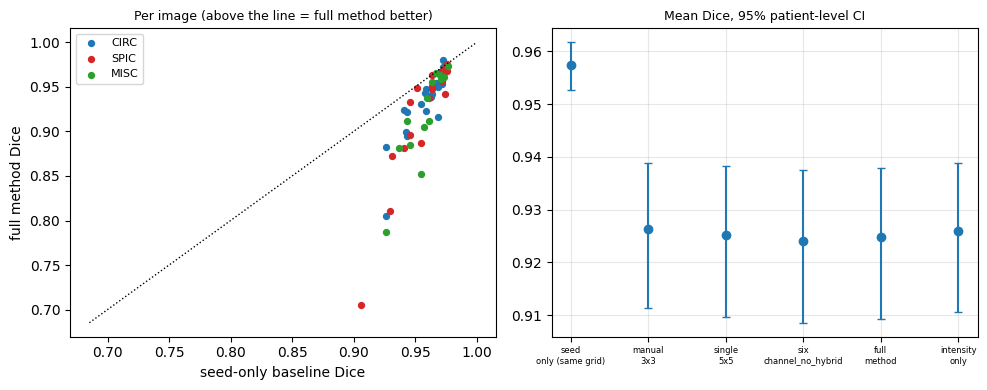

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
a_, b_ = BASE.set_index('image_id')['dice'], FULL.set_index('image_id')['dice']; cc = {'CIRC': 'tab:blue', 'SPIC': 'tab:red', 'MISC': 'tab:green'}
for c in TARGET_CLASSES:
    ids_ = [i for i in a_.index if class_of[i] == c]; ax[0].scatter(a_[ids_], b_[ids_], s=18, color=cc.get(c), label=c)
lim = [min(a_.min(), b_.min()) - 0.02, 1.0]; ax[0].plot(lim, lim, 'k:', lw=1); ax[0].set_xlabel("seed-only baseline Dice"); ax[0].set_ylabel("full method Dice"); ax[0].legend(fontsize=8); ax[0].set_title("Per image (above the line = full method better)", fontsize=9)
x = np.arange(len(METHOD_ORDER)); ax[1].errorbar(x, T2['dice'], yerr=[T2['dice'] - T2['dice_ci_low'], T2['dice_ci_high'] - T2['dice']], fmt='o', capsize=3, color='tab:blue')
ax[1].set_xticks(x); ax[1].set_xticklabels([m.replace('_', '\n', 1) for m in METHOD_ORDER], fontsize=6); ax[1].set_title("Mean Dice, 95% patient-level CI", fontsize=9); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(FIGURES_DIR, f"fig_mias_cv_{RUN_TAG}.png"), dpi=150); plt.show()

In [14]:
def verify_mias2():
    touched_ok = all(not (set(l['touched']) & set(l['test'])) and set(l['touched']) <= (set(f['train_ids']) | set(f['val_ids']))
                     for l, f in zip(sorted(fold_logs, key=lambda x: x['fold']), FOLDS))
    sets = [set(M[m]['image_id']) for m in METHOD_ORDER]
    checks = {
        "every image scored exactly once per method"                 : all(len(M[m]) == len(ALL_IDS) and set(M[m]['image_id']) == set(ALL_IDS) for m in METHOD_ORDER),
        "identical images for every method"                          : all(s == sets[0] for s in sets),
        "every fold's fitting touched only its train and val images" : touched_ok and len(fold_logs) == len(FOLDS),
        "no patient shared between a fold's test and its fitting"    : all(not ({patient_of[i] for i in f['test_ids']} & {patient_of[i] for i in f['train_ids'] + f['val_ids']}) for f in FOLDS),
        "every texture arm in every fold used K = K_FIXED templates"  : all(d['K'] in (0, K_FIXED) for d in diag_all) and any(d['K'] == K_FIXED for d in diag_all),
        "evaluation seeds never use the whole mask"                  : strict >= 0.95,
        "out-of-fold probability map exists for every image"         : set(OOF) == set(ALL_IDS),
        "metrics finite for >= 99% of images"                        : all(M[m]['dice'].notna().mean() >= 0.99 for m in METHOD_ORDER),
        "outputs saved"                                              : all(os.path.exists(os.path.join(OUT_DIR, f)) for f in ("per_image_results.csv", "table2_panelB_mias.csv", "table3_panelB_mias.csv", "mias_paired_ci.csv", "oof_prob_maps.npz", "run_summary.json")),
    }
    print("=" * 60); print(f"MIAS NOTEBOOK 2 VERIFICATION (K = {K_FIXED})"); print("=" * 60); ok = True
    for k, v in checks.items(): print(f"  {'OK  ' if bool(v) else 'FAIL'}  {k}"); ok = ok and bool(v)
    print("=" * 60); print("Cross-validated evaluation complete." if ok else "Review failures."); return ok
verify_mias2()


MIAS NOTEBOOK 2 VERIFICATION (K = 8)
  OK    every image scored exactly once per method
  OK    identical images for every method
  OK    every fold's fitting touched only its train and val images
  OK    no patient shared between a fold's test and its fitting
  OK    every texture arm in every fold used K = K_FIXED templates
  OK    evaluation seeds never use the whole mask
  OK    out-of-fold probability map exists for every image
  OK    metrics finite for >= 99% of images
  OK    outputs saved
Cross-validated evaluation complete.


True